# Scalable ETL Pipeline: UK Road Safety (4.2M+ Records)

## 1. Data Exploration & Quality Profiling
Inspecting samples of `Accident_Information.csv` and `Vehicle_Information.csv` to identify schema structure and data anomalies:
- **Hidden Missing Values**: Strings like `'Data missing or out of range'`, `'Unallocated'`, and `'Not known'` are used instead of `NaN`.
- **High-Null Columns**: Columns exceeding 90% missing values (e.g., `Carriageway_Hazards`) are excluded.
- **Encoded Categories & Numeric Outliers**: `Vehicle_Type` contains numeric strings (`109`, `108`, `106`), and `Engine_Capacity_.CC.` contains extreme outliers (e.g., `2 CC` up to `91,000 CC`).

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text

df_acc_head = pd.read_csv("Accident_Information.csv", nrows=5, encoding='latin1')

print("Accidents Columns:")
print(df_acc_head.columns.tolist())

print("\nFirst 2 rows sample (Transposed):")
display(df_acc_head.head(2).T)

Accidents Columns:
['Accident_Index', '1st_Road_Class', '1st_Road_Number', '2nd_Road_Class', '2nd_Road_Number', 'Accident_Severity', 'Carriageway_Hazards', 'Date', 'Day_of_Week', 'Did_Police_Officer_Attend_Scene_of_Accident', 'Junction_Control', 'Junction_Detail', 'Latitude', 'Light_Conditions', 'Local_Authority_(District)', 'Local_Authority_(Highway)', 'Location_Easting_OSGR', 'Location_Northing_OSGR', 'Longitude', 'LSOA_of_Accident_Location', 'Number_of_Casualties', 'Number_of_Vehicles', 'Pedestrian_Crossing-Human_Control', 'Pedestrian_Crossing-Physical_Facilities', 'Police_Force', 'Road_Surface_Conditions', 'Road_Type', 'Special_Conditions_at_Site', 'Speed_limit', 'Time', 'Urban_or_Rural_Area', 'Weather_Conditions', 'Year', 'InScotland']

First 2 rows sample (Transposed):


,0,1
Accident_Index,200501BS00001,200501BS00002
1st_Road_Class,A,B
1st_Road_Number,3218,450
2nd_Road_Class,NaN,C
2nd_Road_Number,0,0
Accident_Severity,Serious,Slight
Carriageway_Hazards,NaN,NaN
Date,2005-01-04,2005-01-05
Day_of_Week,Tuesday,Wednesday
Did_Police_Officer_Attend_Scene_of_Accident,1,1


In [44]:
df_veh_head = pd.read_csv("Vehicle_Information.csv", nrows=5, encoding='latin1')

print("Vehicles Columns:")
print(df_veh_head.columns.tolist())

print("\nFirst 2 rows sample (Transposed):")
display(df_veh_head.head(2).T)

Vehicles Columns:
['Accident_Index', 'Age_Band_of_Driver', 'Age_of_Vehicle', 'Driver_Home_Area_Type', 'Driver_IMD_Decile', 'Engine_Capacity_.CC.', 'Hit_Object_in_Carriageway', 'Hit_Object_off_Carriageway', 'Journey_Purpose_of_Driver', 'Junction_Location', 'make', 'model', 'Propulsion_Code', 'Sex_of_Driver', 'Skidding_and_Overturning', 'Towing_and_Articulation', 'Vehicle_Leaving_Carriageway', 'Vehicle_Location.Restricted_Lane', 'Vehicle_Manoeuvre', 'Vehicle_Reference', 'Vehicle_Type', 'Was_Vehicle_Left_Hand_Drive', 'X1st_Point_of_Impact', 'Year']

First 2 rows sample (Transposed):


,0,1
Accident_Index,200401BS00001,200401BS00002
Age_Band_of_Driver,26 - 35,26 - 35
Age_of_Vehicle,3.0,NaN
Driver_Home_Area_Type,Urban area,Urban area
Driver_IMD_Decile,4.0,3.0
Engine_Capacity_.CC.,1588.0,NaN
Hit_Object_in_Carriageway,NaN,NaN
Hit_Object_off_Carriageway,NaN,NaN
Journey_Purpose_of_Driver,Data missing or out of range,Data missing or out of range
Junction_Location,Data missing or out of range,Data missing or out of range


In [45]:
df_acc_check = pd.read_csv("Accident_Information.csv", nrows=100000, low_memory=False, encoding='latin1')

print("Shape of Accidents sample:", df_acc_check.shape)
print("\n--- Missing Values (NaN) in Accidents ---")
print(df_acc_check.isnull().sum()[df_acc_check.isnull().sum() > 0])

print("\n--- Unique values in key categorical columns ---")
for col in ['Accident_Severity', 'Urban_or_Rural_Area', 'Road_Surface_Conditions', 'Weather_Conditions', 'Road_Type']:
    print(f"\n{col}:", df_acc_check[col].unique())

print("\n--- Speed Limit Summary ---")
print(df_acc_check['Speed_limit'].describe())

Shape of Accidents sample: (100000, 34)

--- Missing Values (NaN) in Accidents ---
2nd_Road_Class                                 35816
2nd_Road_Number                                  434
Carriageway_Hazards                            98421
Did_Police_Officer_Attend_Scene_of_Accident      162
Latitude                                          31
Location_Easting_OSGR                             31
Location_Northing_OSGR                            31
Longitude                                         31
LSOA_of_Accident_Location                        111
Pedestrian_Crossing-Human_Control                 13
Pedestrian_Crossing-Physical_Facilities           17
Special_Conditions_at_Site                     97721
Time                                               1
dtype: int64

--- Unique values in key categorical columns ---

Accident_Severity: <StringArray>
['Serious', 'Slight', 'Fatal']
Length: 3, dtype: str

Urban_or_Rural_Area: <StringArray>
['Urban', 'Rural', 'Unallocated']
Length: 

In [46]:
df_veh_check = pd.read_csv("Vehicle_Information.csv", nrows=100000, low_memory=False, encoding='latin1')

print("Shape of Vehicles sample:", df_veh_check.shape)
print("\n--- Missing Values (NaN) in Vehicles ---")
print(df_veh_check.isnull().sum()[df_veh_check.isnull().sum() > 0])

print("\n--- Unique values in key vehicle columns ---")
for col in ['Age_Band_of_Driver', 'Sex_of_Driver', 'Vehicle_Type', 'Propulsion_Code']:
    print(f"\n{col}:", df_veh_check[col].unique())

print("\n--- Numeric Columns Summary (Before Cleaning Outliers) ---")
print(df_veh_check[['Age_of_Vehicle', 'Engine_Capacity_.CC.']].describe())

Shape of Vehicles sample: (100000, 24)

--- Missing Values (NaN) in Vehicles ---
Age_of_Vehicle                      16736
Driver_IMD_Decile                   30809
Engine_Capacity_.CC.                12849
Hit_Object_in_Carriageway           95887
Hit_Object_off_Carriageway          91620
model                               21866
Propulsion_Code                     10127
Skidding_and_Overturning            84447
Vehicle_Location.Restricted_Lane       23
dtype: int64

--- Unique values in key vehicle columns ---

Age_Band_of_Driver: <StringArray>
[                     '26 - 35',                      '66 - 75',
                      '36 - 45',                      '46 - 55',
                      '21 - 25', 'Data missing or out of range',
                      '16 - 20',                      '56 - 65',
                      'Over 75',                      '11 - 15',
                       '6 - 10']
Length: 11, dtype: str

Sex_of_Driver: <StringArray>
['Male', 'Female', 'Not known']
Leng

## 2. Transformation & Data Sanitization Layer
Defining modular transformation functions (`transform_accidents` & `transform_vehicles`):
- **Standardizing Missing Labels**: Unifying all missing indicators into `'Unknown'`.
- **Decoding Categories**: Mapping vehicle codes (`109` -> `Car`, `108` -> `Taxi`, `106` -> `Motorcycle over 500cc`).
- **Outlier Sanitization**: Filtering invalid speed limits, vehicle ages (`< 0` or `> 50` years), and engine capacities (`< 50 CC` or `> 15,000 CC`) to `NaN` so SQL `AVG()` calculations remain accurate.

In [47]:
acc_cols = [
    'Accident_Index', 'Accident_Severity', 'Date', 'Day_of_Week',
    'Latitude', 'Longitude', 'Number_of_Casualties', 'Number_of_Vehicles',
    'Road_Type', 'Speed_limit', 'Urban_or_Rural_Area', 
    'Road_Surface_Conditions', 'Weather_Conditions', 'Year'
]

veh_cols = [
    'Accident_Index', 'Age_Band_of_Driver', 'Age_of_Vehicle',
    'Engine_Capacity_.CC.', 'make', 'Propulsion_Code',
    'Sex_of_Driver', 'Vehicle_Type', 'Year'
]

def transform_accidents(df):
    df = df.copy()
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
    
    missing_labels = ['Data missing or out of range', 'Unallocated', 'Unknown']
    df.replace(missing_labels, 'Unknown', inplace=True)
    
    cat_cols = ['Road_Surface_Conditions', 'Weather_Conditions', 'Road_Type', 'Urban_or_Rural_Area']
    for col in cat_cols:
        df[col] = df[col].fillna('Unknown')
        
    df.loc[(df['Speed_limit'] <= 0) | (df['Speed_limit'] > 70), 'Speed_limit'] = np.nan
    
    df.dropna(subset=['Accident_Index', 'Date'], inplace=True)
    df.drop_duplicates(subset=['Accident_Index'], inplace=True)
    return df

def transform_vehicles(df):
    df = df.copy()
    df.rename(columns={'Engine_Capacity_.CC.': 'Engine_Capacity_CC'}, inplace=True)
    
    vehicle_map = {
        '109': 'Car',
        '108': 'Taxi/Private hire car',
        '106': 'Motorcycle over 500cc'
    }
    df['Vehicle_Type'] = df['Vehicle_Type'].replace(vehicle_map)
    
    missing_labels = ['Data missing or out of range', 'Not known', 'Unallocated']
    df.replace(missing_labels, 'Unknown', inplace=True)
    
    cat_cols = ['Propulsion_Code', 'make', 'Vehicle_Type', 'Age_Band_of_Driver', 'Sex_of_Driver']
    for col in cat_cols:
        df[col] = df[col].fillna('Unknown')
        
    df.loc[(df['Age_of_Vehicle'] < 0) | (df['Age_of_Vehicle'] > 50), 'Age_of_Vehicle'] = np.nan
    df.loc[(df['Engine_Capacity_CC'] < 50) | (df['Engine_Capacity_CC'] > 15000), 'Engine_Capacity_CC'] = np.nan
    
    df.dropna(subset=['Accident_Index'], inplace=True)
    return df

df_acc_clean_test = transform_accidents(df_acc_check[acc_cols])
df_veh_clean_test = transform_vehicles(df_veh_check[veh_cols])

print("Cleaned Accidents Sample Shape:", df_acc_clean_test.shape)
print("Cleaned Vehicles Sample Shape:", df_veh_clean_test.shape)

print("\nUpdated Vehicle Types:\n", df_veh_clean_test['Vehicle_Type'].value_counts().head(5))

print("\nNumeric Columns Summary (After Cleaning Outliers):")
print(df_veh_clean_test[['Age_of_Vehicle', 'Engine_Capacity_CC']].describe())

print("\nRemaining NaNs in Accidents:\n", df_acc_clean_test.isnull().sum()[df_acc_clean_test.isnull().sum() > 0])
print("\nRemaining NaNs in Vehicles:\n", df_veh_clean_test.isnull().sum()[df_veh_clean_test.isnull().sum() > 0])

Cleaned Accidents Sample Shape: (100000, 14)
Cleaned Vehicles Sample Shape: (100000, 9)

Updated Vehicle Types:
 Vehicle_Type
Car                                     69635
Motorcycle over 500cc                    6521
Bus or coach (17 or more pass seats)     6418
Goods 7.5 tonnes mgw and over            5410
Van / Goods 3.5 tonnes mgw or under      4977
Name: count, dtype: int64

Numeric Columns Summary (After Cleaning Outliers):
       Age_of_Vehicle  Engine_Capacity_CC
count    83264.000000        86270.000000
mean         6.496013         2280.561551
std          4.652905         2276.079197
min          1.000000           50.000000
25%          3.000000         1299.000000
50%          6.000000         1721.000000
75%          9.000000         1998.000000
max         49.000000        15000.000000

Remaining NaNs in Accidents:
 Latitude     31
Longitude    31
dtype: int64

Remaining NaNs in Vehicles:
 Age_of_Vehicle        16736
Engine_Capacity_CC    13730
dtype: int64


## 3. Scalable Chunked ETL & Database Indexing
- **Chunked Ingestion**: Reading and transforming raw CSVs in batches of `100,000` rows (`latin1` encoding) into a local **SQLite Database** (`uk_road_safety.db`).
- **Cross-Chunk Deduplication & Indexing**: Removing any duplicate `Accident_Index` across chunks using SQL `ROWID` and creating a `UNIQUE INDEX` on `accidents(Accident_Index)` alongside indexes on `vehicles(Accident_Index)` and `Year`.

In [48]:
engine = create_engine("sqlite:///uk_road_safety.db")

def run_etl_pipeline(acc_csv, veh_csv, chunk_size=100000):
    first_chunk = True
    total_acc = 0
    
    for chunk in pd.read_csv(acc_csv, usecols=acc_cols, chunksize=chunk_size, low_memory=False, encoding='latin1'):
        clean_chunk = transform_accidents(chunk)
        mode = 'replace' if first_chunk else 'append'
        clean_chunk.to_sql('accidents', con=engine, if_exists=mode, index=False)
        first_chunk = False
        total_acc += len(clean_chunk)
        print(f"Accidents loaded: {total_acc}")
        
    first_chunk = True
    total_veh = 0
    
    for chunk in pd.read_csv(veh_csv, usecols=veh_cols, chunksize=chunk_size, low_memory=False, encoding='latin1'):
        clean_chunk = transform_vehicles(chunk)
        mode = 'replace' if first_chunk else 'append'
        clean_chunk.to_sql('vehicles', con=engine, if_exists=mode, index=False)
        first_chunk = False
        total_veh += len(clean_chunk)
        print(f"Vehicles loaded: {total_veh}")
        
    with engine.connect() as conn:
        conn.execute(text("""
            DELETE FROM accidents 
            WHERE rowid NOT IN (
                SELECT MIN(rowid) 
                FROM accidents 
                GROUP BY Accident_Index
            );
        """))
        conn.execute(text("CREATE UNIQUE INDEX IF NOT EXISTS idx_acc_id ON accidents(Accident_Index);"))
        conn.execute(text("CREATE INDEX IF NOT EXISTS idx_veh_id ON vehicles(Accident_Index);"))
        conn.execute(text("CREATE INDEX IF NOT EXISTS idx_acc_year ON accidents(Year);"))
        conn.commit()
        
    print(f"\nETL Completed Successfully! Total Accidents: {total_acc} | Total Vehicles: {total_veh}")

run_etl_pipeline("Accident_Information.csv", "Vehicle_Information.csv")

Accidents loaded: 100000
Accidents loaded: 200000
Accidents loaded: 300000
Accidents loaded: 400000
Accidents loaded: 500000
Accidents loaded: 600000
Accidents loaded: 700000
Accidents loaded: 800000
Accidents loaded: 900000
Accidents loaded: 1000000
Accidents loaded: 1100000
Accidents loaded: 1200000
Accidents loaded: 1300000
Accidents loaded: 1400000
Accidents loaded: 1500000
Accidents loaded: 1600000
Accidents loaded: 1700000
Accidents loaded: 1800000
Accidents loaded: 1900000
Accidents loaded: 2000000
Accidents loaded: 2047256
Vehicles loaded: 100000
Vehicles loaded: 200000
Vehicles loaded: 300000
Vehicles loaded: 400000
Vehicles loaded: 500000
Vehicles loaded: 600000
Vehicles loaded: 700000
Vehicles loaded: 800000
Vehicles loaded: 900000
Vehicles loaded: 1000000
Vehicles loaded: 1100000
Vehicles loaded: 1200000
Vehicles loaded: 1300000
Vehicles loaded: 1400000
Vehicles loaded: 1500000
Vehicles loaded: 1600000
Vehicles loaded: 1700000
Vehicles loaded: 1800000
Vehicles loaded: 19000

## 4. Automated SQL Reporting
Generating 4 analytical reports directly from SQLite:
1. **Yearly Severity Summary**: Annual accident and casualty trends by severity.
2. **Speed Limit & Area Analysis**: Urban vs. Rural casualty rates across speed limits.
3. **Vehicle & Driver Demographics (`INNER JOIN`)**: Using `COUNT(DISTINCT a.Accident_Index)` to prevent join fan-out duplication when multiple vehicles of the same group are involved in a single accident.
4. **Vehicle Make & Fuel Risk Rate**: Calculating severe/fatal accident percentages (`Severe_Fatal_Rate_Pct`) per manufacturer.

In [49]:
query_yearly_summary = """
SELECT 
    Year,
    Accident_Severity,
    COUNT(Accident_Index) AS Total_Accidents,
    SUM(Number_of_Casualties) AS Total_Casualties,
    ROUND(AVG(Number_of_Casualties), 2) AS Avg_Casualties_Per_Accident,
    ROUND(AVG(Number_of_Vehicles), 2) AS Avg_Vehicles_Involved
FROM accidents
GROUP BY Year, Accident_Severity
ORDER BY Year DESC, Total_Accidents DESC;
"""

df_report_yearly = pd.read_sql_query(query_yearly_summary, engine)
display(df_report_yearly.head(15))

,Year,Accident_Severity,Total_Accidents,Total_Casualties,Avg_Casualties_Per_Accident,Avg_Vehicles_Involved
0,2017,Slight,105772,137013,1.30,1.86
1,2017,Serious,22534,31157,1.38,1.72
2,2017,Fatal,1676,2823,1.68,1.77
3,2016,Slight,113201,147921,1.31,1.87
4,2016,Serious,21725,30453,1.40,1.72
5,2016,Fatal,1695,3010,1.78,1.78
6,2015,Slight,118402,155174,1.31,1.86
7,2015,Serious,20038,28175,1.41,1.71
8,2015,Fatal,1616,2840,1.76,1.79
9,2014,Slight,123988,162555,1.31,1.86


In [50]:
query_speed_urban = """
SELECT 
    Urban_or_Rural_Area,
    Speed_limit,
    COUNT(Accident_Index) AS Total_Accidents,
    SUM(Number_of_Casualties) AS Total_Casualties,
    ROUND(AVG(Number_of_Casualties), 2) AS Avg_Casualties_Per_Accident
FROM accidents
WHERE Speed_limit IS NOT NULL AND Urban_or_Rural_Area != 'Unknown'
GROUP BY Urban_or_Rural_Area, Speed_limit
HAVING Total_Accidents > 100
ORDER BY Urban_or_Rural_Area, Speed_limit ASC;
"""

df_report_speed = pd.read_sql_query(query_speed_urban, engine)
display(df_report_speed)

,Urban_or_Rural_Area,Speed_limit,Total_Accidents,Total_Casualties,Avg_Casualties_Per_Accident
0,Rural,20.0,2874,3468,1.21
1,Rural,30.0,169199,222321,1.31
2,Rural,40.0,74203,108849,1.47
3,Rural,50.0,48253,74119,1.54
4,Rural,60.0,301936,458721,1.52
5,Rural,70.0,128271,202125,1.58
6,Urban,20.0,35525,41443,1.17
7,Urban,30.0,1136898,1429630,1.26
8,Urban,40.0,94146,132311,1.41
9,Urban,50.0,21223,30462,1.44


In [51]:
query_vehicles_drivers = """
SELECT 
    v.Vehicle_Type,
    v.Age_Band_of_Driver,
    v.Sex_of_Driver,
    COUNT(v.Accident_Index) AS Total_Vehicles_Involved,
    COUNT(DISTINCT a.Accident_Index) AS Distinct_Accidents,
    SUM(CASE WHEN a.Accident_Severity IN ('Serious', 'Fatal') THEN 1 ELSE 0 END) AS Severe_or_Fatal_Involved,
    ROUND(AVG(v.Age_of_Vehicle), 1) AS Avg_Vehicle_Age_Years,
    ROUND(AVG(v.Engine_Capacity_CC), 0) AS Avg_Engine_CC
FROM vehicles v
INNER JOIN accidents a ON v.Accident_Index = a.Accident_Index
WHERE v.Vehicle_Type != 'Unknown' 
  AND v.Age_Band_of_Driver != 'Unknown'
  AND v.Sex_of_Driver IN ('Male', 'Female')
GROUP BY v.Vehicle_Type, v.Age_Band_of_Driver, v.Sex_of_Driver
ORDER BY Total_Vehicles_Involved DESC
LIMIT 20;
"""

df_report_vehicles = pd.read_sql_query(query_vehicles_drivers, engine)
display(df_report_vehicles)

,Vehicle_Type,Age_Band_of_Driver,Sex_of_Driver,Total_Vehicles_Involved,Distinct_Accidents,Severe_or_Fatal_Involved,Avg_Vehicle_Age_Years,Avg_Engine_CC
0,Car,26 - 35,Male,186893,178518,23175,7.7,1802.0
1,Car,36 - 45,Male,169181,162253,21055,7.2,1888.0
2,Car,46 - 55,Male,136092,131362,18081,7.1,1898.0
3,Car,26 - 35,Female,126017,122332,11993,7.0,1609.0
4,Car,36 - 45,Female,119711,116494,11927,6.7,1700.0
5,Car,21 - 25,Male,104597,102228,14642,8.1,1646.0
6,Car,46 - 55,Female,91437,89441,10088,6.7,1651.0
7,Car,56 - 65,Male,90576,88587,13180,6.9,1870.0
8,Car,16 - 20,Male,75079,73810,10808,8.5,1426.0
9,Car,21 - 25,Female,72080,70861,6817,7.1,1424.0


In [52]:
query_car_makes = """
SELECT 
    v.make AS Vehicle_Make,
    v.Propulsion_Code AS Fuel_Type,
    COUNT(v.Accident_Index) AS Total_Vehicles_Involved,
    COUNT(DISTINCT a.Accident_Index) AS Distinct_Accidents,
    ROUND(AVG(v.Age_of_Vehicle), 1) AS Avg_Vehicle_Age,
    ROUND(AVG(v.Engine_Capacity_CC), 0) AS Avg_Engine_CC,
    SUM(CASE WHEN a.Accident_Severity IN ('Serious', 'Fatal') THEN 1 ELSE 0 END) AS Severe_or_Fatal_Count,
    ROUND(SUM(CASE WHEN a.Accident_Severity IN ('Serious', 'Fatal') THEN 1.0 ELSE 0.0 END) * 100 / COUNT(v.Accident_Index), 2) AS Severe_Fatal_Rate_Pct
FROM vehicles v
INNER JOIN accidents a ON v.Accident_Index = a.Accident_Index
WHERE v.make != 'Unknown' AND v.Propulsion_Code != 'Unknown'
GROUP BY v.make, v.Propulsion_Code
ORDER BY Total_Vehicles_Involved DESC
LIMIT 15;
"""

df_report_makes = pd.read_sql_query(query_car_makes, engine)
display(df_report_makes)

,Vehicle_Make,Fuel_Type,Total_Vehicles_Involved,Distinct_Accidents,Avg_Vehicle_Age,Avg_Engine_CC,Severe_or_Fatal_Count,Severe_Fatal_Rate_Pct
0,VAUXHALL,Petrol,136719,133146,7.6,1465.0,16555,12.11
1,FORD,Petrol,110927,107967,8.2,1505.0,13488,12.16
2,FORD,Heavy oil,95144,92708,5.6,1926.0,12135,12.75
3,HONDA,Petrol,86091,84957,8.1,1058.0,17016,19.77
4,VAUXHALL,Heavy oil,73539,72146,5.4,1773.0,8964,12.19
5,RENAULT,Petrol,66482,65661,7.9,1412.0,7785,11.71
6,PEUGEOT,Petrol,65417,64584,7.9,1347.0,8099,12.38
7,VOLKSWAGEN,Heavy oil,59934,58825,5.9,1915.0,7391,12.33
8,TOYOTA,Petrol,51624,51070,8.1,1512.0,5964,11.55
9,MERCEDES,Heavy oil,50938,50159,5.4,3631.0,7200,14.13


## 5. Visual Summary Dashboard & Report Export
Visualizing the 4 core reports into `UK_Road_Safety_Dashboard.png` and exporting all summary tables to standalone `.csv` files and a multi-sheet Excel workbook (`UK_Road_Safety_Summary_Report.xlsx`).

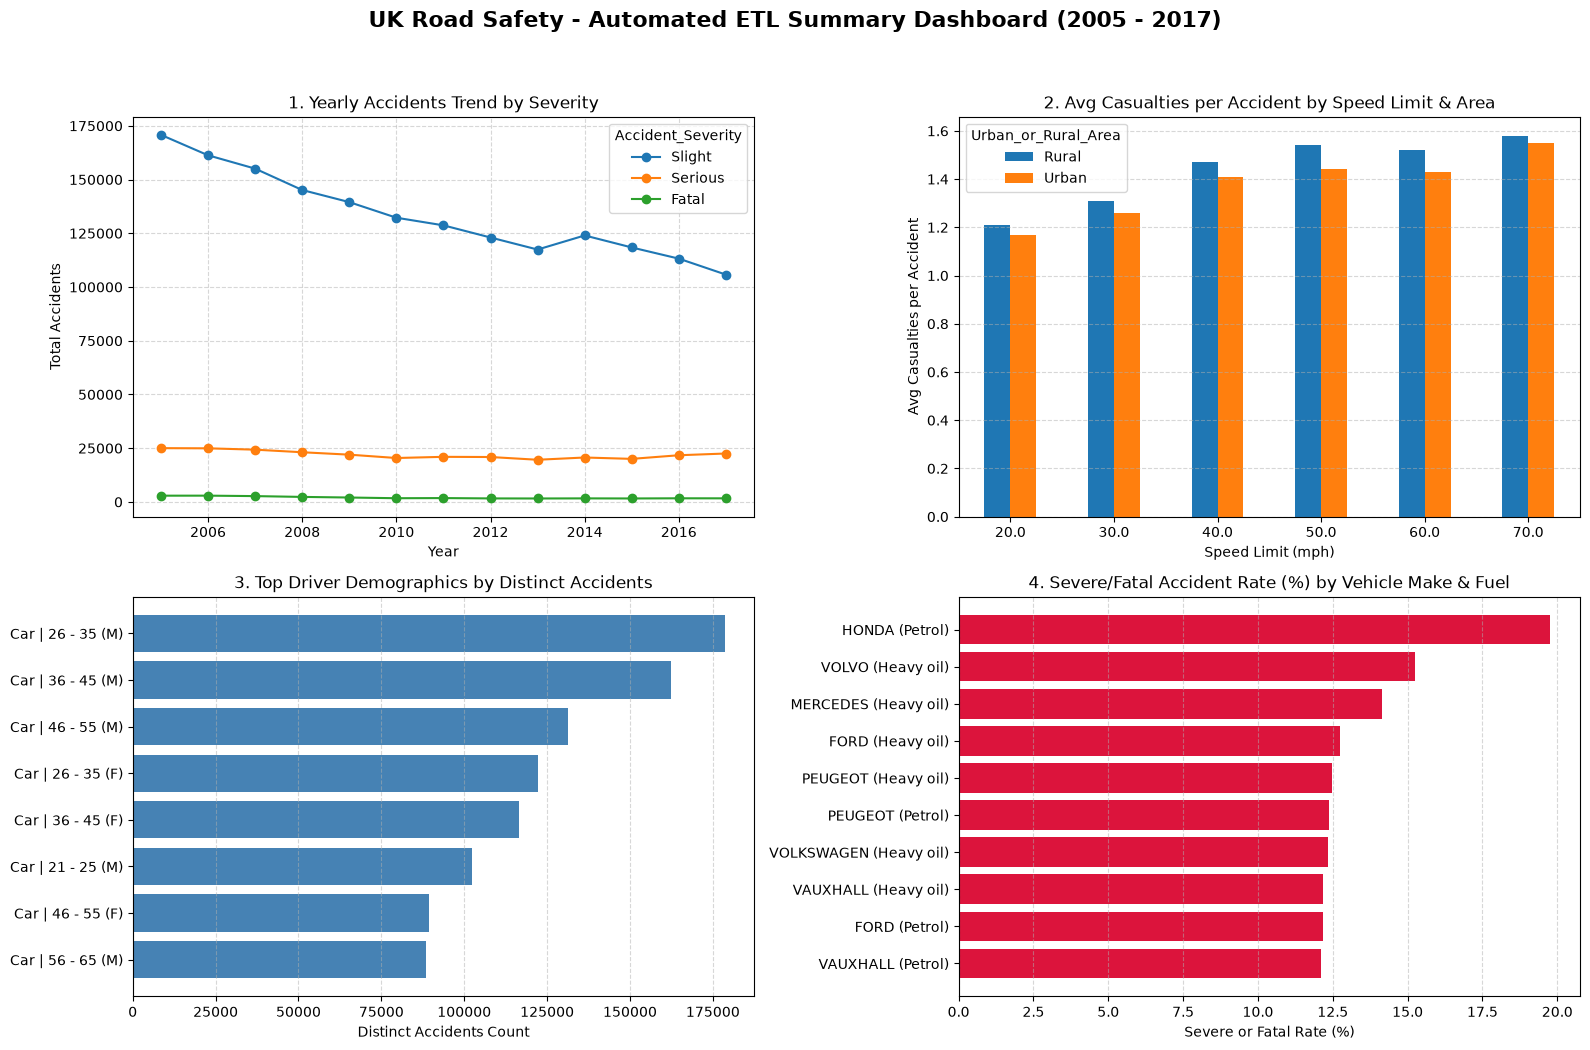

In [53]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle('UK Road Safety - Automated ETL Summary Dashboard (2005 - 2017)', fontsize=16, fontweight='bold')

yearly_pivot = df_report_yearly.pivot(index='Year', columns='Accident_Severity', values='Total_Accidents')
yearly_pivot[['Slight', 'Serious', 'Fatal']].plot(kind='line', marker='o', ax=axes[0, 0])
axes[0, 0].set_title('1. Yearly Accidents Trend by Severity')
axes[0, 0].set_xlabel('Year')
axes[0, 0].set_ylabel('Total Accidents')
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

speed_pivot = df_report_speed.pivot(index='Speed_limit', columns='Urban_or_Rural_Area', values='Avg_Casualties_Per_Accident')
speed_pivot.plot(kind='bar', ax=axes[0, 1], rot=0)
axes[0, 1].set_title('2. Avg Casualties per Accident by Speed Limit & Area')
axes[0, 1].set_xlabel('Speed Limit (mph)')
axes[0, 1].set_ylabel('Avg Casualties per Accident')
axes[0, 1].grid(axis='y', linestyle='--', alpha=0.5)

top_drivers = df_report_vehicles.head(8).copy()
top_drivers['Group'] = top_drivers['Vehicle_Type'].str[:10] + ' | ' + top_drivers['Age_Band_of_Driver'] + ' (' + top_drivers['Sex_of_Driver'].str[0] + ')'
axes[1, 0].barh(top_drivers['Group'][::-1], top_drivers['Distinct_Accidents'][::-1], color='steelblue')
axes[1, 0].set_title('3. Top Driver Demographics by Distinct Accidents')
axes[1, 0].set_xlabel('Distinct Accidents Count')
axes[1, 0].grid(axis='x', linestyle='--', alpha=0.5)

top_makes = df_report_makes.sort_values(by='Severe_Fatal_Rate_Pct', ascending=True).tail(10)
make_labels = top_makes['Vehicle_Make'] + ' (' + top_makes['Fuel_Type'] + ')'
axes[1, 1].barh(make_labels, top_makes['Severe_Fatal_Rate_Pct'], color='crimson')
axes[1, 1].set_title('4. Severe/Fatal Accident Rate (%) by Vehicle Make & Fuel')
axes[1, 1].set_xlabel('Severe or Fatal Rate (%)')
axes[1, 1].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('UK_Road_Safety_Dashboard.png', dpi=300)
plt.show()

In [54]:
reports_dict = {
    "Yearly_Severity_Summary": df_report_yearly,
    "Speed_and_Area_Analysis": df_report_speed,
    "Vehicles_and_Drivers": df_report_vehicles,
    "Top_Vehicle_Makes": df_report_makes
}

excel_filename = "UK_Road_Safety_Summary_Report.xlsx"

with pd.ExcelWriter(excel_filename, engine='openpyxl') as writer:
    for sheet_name, df_rep in reports_dict.items():
        df_rep.to_excel(writer, sheet_name=sheet_name, index=False)
        csv_filename = f"{sheet_name}.csv"
        df_rep.to_csv(csv_filename, index=False)
        print(f"Saved updated report: {csv_filename}")

print(f"\nAll corrected reports successfully compiled into: {excel_filename}")

Saved updated report: Yearly_Severity_Summary.csv
Saved updated report: Speed_and_Area_Analysis.csv
Saved updated report: Vehicles_and_Drivers.csv
Saved updated report: Top_Vehicle_Makes.csv

All corrected reports successfully compiled into: UK_Road_Safety_Summary_Report.xlsx
